# Canine Cutaneous Tumor Segmentation

## Import Packages

In [2]:
import torch
torch.cuda.empty_cache()

In [3]:
import sys 
sys.path.insert(0, '..')
from fastai.utils.collect_env import show_install
from evaluation.metrics import *
from fastai.callbacks.tracker import SaveModelCallback
from slide.slide_helper import SlideSegmentationItemList, SlideSegmentationLabelList
from slide.process_slides import *
from torchsummary import summary
from custom_loss_functions import ComboLoss
from custom_callbacks import UpdateProbabilitiesCallback
from torchvision import transforms

## Label function

In [4]:
def get_y_func(x):
    return x

## Confirm that you have a GPU up and running 

In [5]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# show_install()
device

device(type='cuda')

## Define model input parameters


In [6]:
patch_size = 512
patches_per_slide = 5 #10 # define number of pathes sampled per slide for each pseudo-epoch
batch_size = 6 #8
level = 0 # resolution level of image pyramid (higher level corresponds to lower resoution)
lr = 1e-4
encoder = models.resnet18

## Define paths of slide folder and annotation JSON

In [7]:
# target_folder = Path("../catch")
# annotation_file = "../CATCH.json"

In [8]:
target_folder = "/home/klose/Data/crops"
annotation_file = "/home/klose/Data/CMC.json"

## Define dict to match annotation classes to classes used for training
> Label classes that shall be excluded from training with -1

In [9]:
# label_dict = {'Bg': 0, 'Bone': -1, 'Cartilage': -1, 'Dermis': 1, 'Epidermis': 2, 'Subcutis': 3, 'Inflamm/Necrosis': 4,'Melanoma': 5, 'Plasmacytoma': 5,'Mast Cell Tumor': 5, 'PNST': 5, 'SCC': 5, 'Trichoblastoma': 5, 'Histiocytoma': 5}

In [10]:
#mein eigenes 
#Label Dict, -1 is not relevant 
label_dict = {'Lumen': -1, 'Tumor': 0, 
              'Tub. 1S - Pleo 1': -1, 'Tub. 1S - Pleo 2': -1, 'Tub. 1S - Pleo 3': -1, 
              'Tub. PluriS - Pleo 1': -1, 'Tub. PluriS - Pleo 2': -1, 'Tub. PluriS - Pleo 3':-1,
             'Tubulopap. - Pleo 1': -1, 'Tubulopap. - Pleo 2': -1, 'Tubulopap. - Pleo 3': -1, 
            'Solid - Pleo 1': -1, 'Solid - Pleo 2': -1, 'Solid - Pleo 3': -1,
             'Nekrose / Entzündung': -1, 'Normal': 0, 'Gefäße - Frei': -1, 'Gefäße - Metastase': -1,
             'Tumorstroma': -1, 'Ignore': -1, 'Annotationskasten': 0,
             'Micropap. P1': -1, 'Micropap. P2': -1, 'Micropap. P3': -1,
             'Kasten - vereinfacht': -1, 'Kasten - Test': -1, 
              'A1 - B1': -1,'A1 - B2': -1, 'A1 - B3': -1, 'A2 - B1': -1,'A2 - B2': -1,'A2 - B3':-1, 'A3 - B1':-1, 'A3 - B2':-1,'A3 - B3':-1}

## Load slides using custom SlideContainer format and split into train, validation and test set

In [11]:
train_files, valid_files, _ = load_slides(["train","valid"], patch_size,label_dict, level, target_folder, annotation_file = annotation_file, dataset_type='segmentation')
train_data = create_patches(train_files, patches_per_slide)
valid_data = create_patches(valid_files, patches_per_slide)

  0%|                                                                       | 0/115 [00:00<?, ?it/s]

labels {2, 3, 6, 12, 15, 16, 17, 19}
len labels 8
self /home/klose/Data/crops/CP_CMC_19_133 D.svs_2.tiff


  1%|▌                                                              | 1/115 [00:00<01:38,  1.16it/s]

labels {2, 14, 15, 16, 20}
len labels 5
self /home/klose/Data/crops/CP_CMC_16_2653 C.svs_1.tiff


  2%|█                                                              | 2/115 [00:03<02:31,  1.34s/it]

...

 88%|█████████████████████████████████████████████████████▌       | 101/115 [00:22<00:02,  6.79it/s]

labels {18, 20, 15}
len labels 3
self /home/klose/Data/crops/CP_CMC_19_6906 1C.svs_2.tiff
labels {2, 5, 8, 12, 13, 14, 15, 19}
len labels 8
self /home/klose/Data/crops/CP_CMC_20_1942 A.svs_1.tiff


 89%|██████████████████████████████████████████████████████       | 102/115 [00:22<00:02,  6.22it/s]

labels {2, 13, 14, 15, 19}
len labels 5
self /home/klose/Data/crops/CP_CMC_21_5678.svs_1.tiff
labels {2, 12, 15, 17, 18, 19}
len labels 6
self /home/klose/Data/crops/CP_CMC_17_4319 1N.svs_1.tiff


100%|█████████████████████████████████████████████████████████████| 115/115 [00:23<00:00,  4.98it/s]


## Use standard [transforms](https://fastai1.fast.ai/vision.transform.html) for augmentation provided by fastai  

In [12]:
tfms = get_transforms(do_flip=True,
                      flip_vert=True,
                      max_rotate=45,
                      max_lighting=0.15,
                      max_zoom=2)

## Create fastai databunch (todod: Klassen anpassen 

In [13]:
train = SlideSegmentationItemList(train_data)
valid = SlideSegmentationItemList(valid_data)
path = Path('.')
item_list = ItemLists(path, train, valid)
item_list = item_list.label_from_func(get_y_func, classes=['Bg', 'Dermis', 'Epidermis','Subcutis', 'Inflamm/Necrosis', 'Tumor'],label_cls=SlideSegmentationLabelList)

## Normalize with training set statistics

In [14]:
data = item_list.transform(tfms, size=patch_size, tfm_y=True).databunch(bs=batch_size, no_check=True, num_workers=0).normalize(([0.7587, 0.5718, 0.6572],[0.0866, 0.1118, 0.0990])) # For Windows num_workers has to be set to 0

## Let's have a look at the data

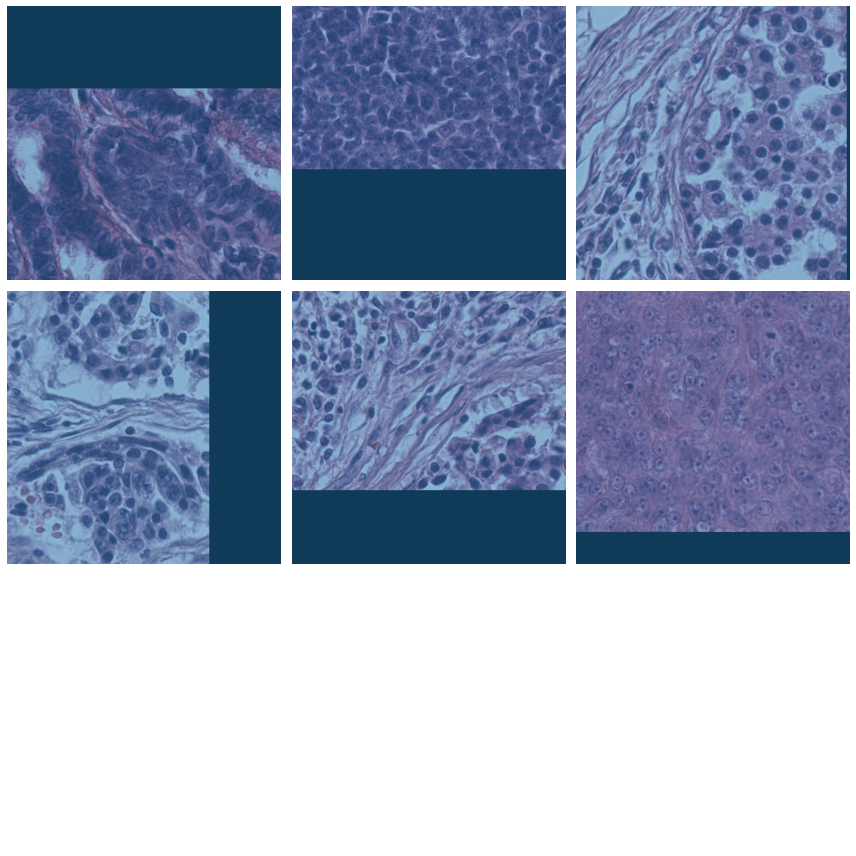

In [15]:
data.show_batch(ds_type=DatasetType.Valid)

## Initalize UNet learner

Quelle: 
Fastai Anwendung: https://walkwithfastai.com/Segmentation (Unet - self attention layer und andere neue Methoden)

In [16]:
# learn = unet_learner(data, encoder, metrics=[iou, background_iou, dermis_iou, epidermis_iou, subcutis_iou, infl_nec_iou, tumor_iou],callback_fns=[ShowGraph])
#metrics kommen aus dem metrics.py Modul, iou = Intersectin over Union 
learn = unet_learner(data, encoder, metrics=[iou, background_iou,tumor_iou],callback_fns=[ShowGraph])
#learn = unet_learner(data, encoder, metrics=[iou, background_iou],callback_fns=[ShowGraph])
learn.loss_func = ComboLoss()
up_cb = UpdateProbabilitiesCallback(learn, train_files)

## Start training

In [17]:
learn.fit_one_cycle(2, lr,  callbacks=[SaveModelCallback(learn, every='improvement', monitor='iou',name='segmentation_learner'),up_cb])
#Problem list index out of range-> eventuell weil bei einem Bild die Labels fehlen ? - Ja 

epoch,train_loss,valid_loss,iou,background_iou,tumor_iou,time


RuntimeError: CUDA out of memory. Tried to allocate 20.00 MiB (GPU 0; 9.75 GiB total capacity; 1019.23 MiB already allocated; 6.38 MiB free; 1.01 GiB reserved in total by PyTorch)

## Let's have a look at some results

In [73]:
valid_files[0].get_y_patch(300//np.power(4,level),300//np.power(4,level))

array([[ 0,  0,  0,  0, ..., -1, -1, -1, -1],
       [ 0,  0,  0,  0, ..., -1, -1, -1, -1],
       [ 0,  0,  0,  0, ..., -1, -1, -1, -1],
       [ 0,  0,  0,  0, ..., -1, -1, -1, -1],
       ...,
       [-1, -1, -1, -1, ..., -1, -1, -1, -1],
       [-1, -1, -1, -1, ..., -1, -1, -1, -1],
       [-1, -1, -1, -1, ..., -1, -1, -1, -1],
       [-1, -1, -1, -1, ..., -1, -1, -1, -1]], dtype=int8)

In [74]:
def show_patch_results (learn, device, image_container, x_min, y_min, level, patch_size):
    lut = []
    lut.append([255, 255, 255]) # Background
    lut.append([0, 0, 255]) # Dermis
    lut.append([0, 255, 255]) # Epidermis
    lut.append([255, 0, 0]) # Subcutis
    lut.append([255, 20, 147]) # Inflamm/Necrosis
    lut.append([255, 128, 0]) # Tumor
    lut.append([255, 255, 255]) # Excluded
    lut = np.array(lut).astype(int)
    
    print("lut", lut)

    image = np.array(image_container.slide.read_region(location=(x_min, y_min), level=level, size=(patch_size, patch_size)))[:, :, :3]
    patch = pil2tensor(image / 255., np.float32)
    patch = transforms.Normalize(*learn.data.stats)(patch)
    gt = image_container.get_y_patch(x_min//np.power(4,level), y_min//np.power(4,level)) #gt = ground trouth 
    
    print("gt", gt)

    with torch.no_grad():
        prediction = learn.model.eval()(torch.stack([patch]).to(device=device))
        prediction = torch.softmax(prediction, dim=1)
        prediction = prediction.argmax(dim=1)[None]
        prediction = np.squeeze(prediction.cpu(), 0)
        
        print("prediction", prediction)

        _, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 15))
        ax[0].set_title("Image")
        ax[1].set_title("GT")
        ax[2].set_title("Prediction")

        ax[0].imshow(image)
        ax[1].imshow(lut[gt])
        ax[2].imshow(np.squeeze(lut[prediction], 0))

lut [[255 255 255]
 [  0   0 255]
 [  0 255 255]
 [255   0   0]
 [255  20 147]
 [255 128   0]
 [255 255 255]]
gt [[ 0  0  0  0 ... -1 -1 -1 -1]
 [ 0  0  0  0 ... -1 -1 -1 -1]
 [ 0  0  0  0 ... -1 -1 -1 -1]
 [ 0  0  0  0 ... -1 -1 -1 -1]
 ...
 [-1 -1 -1 -1 ... -1 -1 -1 -1]
 [-1 -1 -1 -1 ... -1 -1 -1 -1]
 [-1 -1 -1 -1 ... -1 -1 -1 -1]
 [-1 -1 -1 -1 ... -1 -1 -1 -1]]
prediction tensor([[[4, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         ...,
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0],
         [0, 0, 0,  ..., 0, 0, 0]]])
lut [[255 255 255]
 [  0   0 255]
 [  0 255 255]
 [255   0   0]
 [255  20 147]
 [255 128   0]
 [255 255 255]]
gt [[ 0  0  0  0 ...  0 -1 -1  0]
 [ 0  0  0  0 ... -1 -1 -1  0]
 [ 0  0  0  0 ... -1 -1 -1  0]
 [ 0  0  0  0 ... -1 -1  0  0]
 ...
 [ 0  0  0  0 ...  0  0  0  0]
 [ 0  0  0  0 ...  0  0  0  0]
 [ 0  0  0  0 ...  0  0  0  0]
 [ 0  0  0  0 ...  0  0  0  0]]
prediction tensor([[[4, 0, 0,

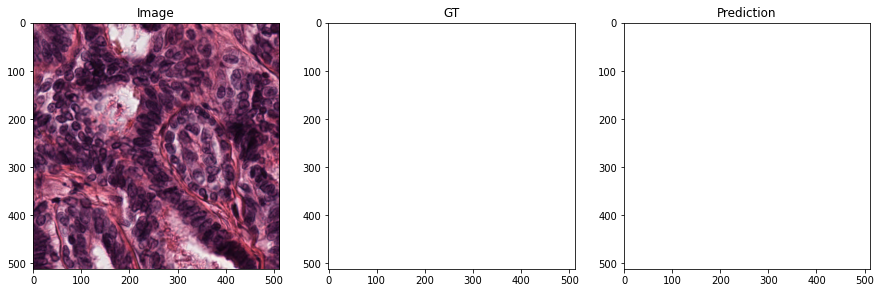

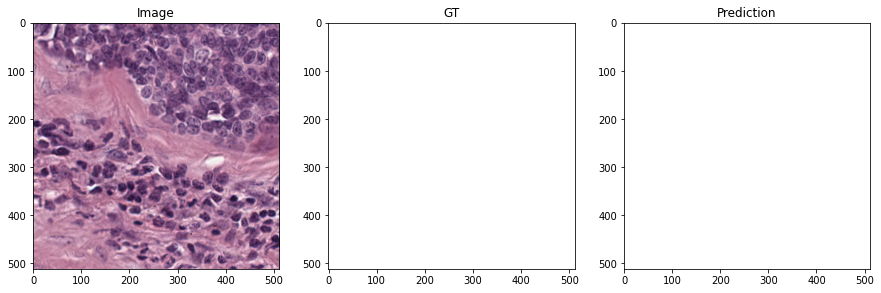

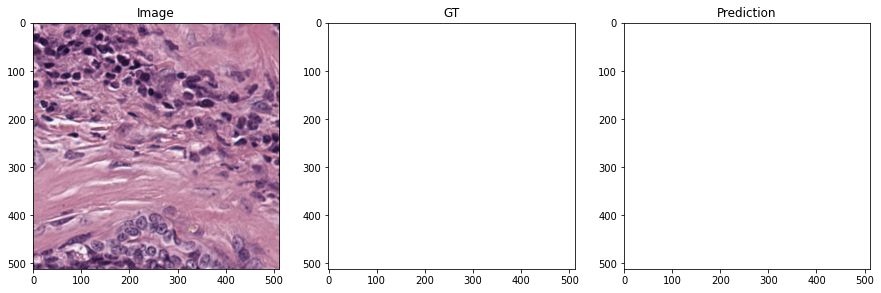

In [75]:
show_patch_results(learn, device, valid_files[0], 300, 300, level, patch_size)
show_patch_results(learn, device, valid_files[1], 500, 400, level, patch_size)
show_patch_results(learn, device, valid_files[1], 200, 500, level, patch_size)

## Export learner

In [ ]:
learn.export('segmentation_learner.pkl')